# Reading a SCAT vault as a graph

A descriptive notebook for a data or network scientist, and a thin consumer of the `scat_analysis` package (see `../README.md`).
It loads a SCAT vault, builds a typed graph (stakeholder group, concern, affordance, technology, plus `conflicts` among concerns and the coded scenario and architecture records as provenance), and shows six analyses on two vaults: the template's case study (small, real structure) and a synthetic water-cooperative vault (richer, invented, with planted patterns).

Stance: the notebook **describes** the graph. Every analysis block ends with *Reads as* (what the picture says) and *Does not mean* (what it must not be taken to say). Nothing here orders stories, groups or architectures as more or less good; only counts and structure.

Before trusting anything here on your own vault: run `scat check` until it passes, and have the coder sign off the content. Run top to bottom, offline.

In [1]:
import os
os.environ.setdefault("MPLBACKEND", "Agg")            # headless-safe; Jupyter's inline backend overrides it interactively
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display

import scat_analysis as sa
from scat_analysis import plots

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

# Path variables: change these to point at any vault. Defaults are copies committed beside the notebook.
CASE_STUDY = Path("case-study")              # copy of the template's case study, read-only
SYNTHETIC  = Path("../synth/vault")          # generated by ../synth/generate.py
STATUS     = None                            # e.g. "done" to keep only signed-off pages; None keeps every page

VAULTS = {"case study": sa.load_graph(CASE_STUDY, STATUS), "synthetic": sa.load_graph(SYNTHETIC, STATUS)}
for name, m in VAULTS.items():
    print(name, "| pages by status:", m.status_counts, "| dangling relation pages:", m.dangling)
display(pd.concat({k: m.summary()["count"] for k, m in VAULTS.items()}, axis=1))

case study | pages by status: {'done': 28, None: 7} | dangling relation pages: []
synthetic | pages by status: {'done': 156, None: 7} | dangling relation pages: []


,case study,synthetic
item,,
group,3,7
concern,3,18
affordance,3,13
technology,3,10
heldby edges,2,40
addresses edges,3,31
attributes edges,3,23
conflict pairs,1,5
coded records,4,7


## 0. How the graph is built

- **Loader.** `sa.load_graph(root, status=None)` reads the vault through `scat_kg` (its one internal reach is `scat_kg.vault.read_vault`; core has no public loader) and takes each page's already-parsed links. No frontmatter is parsed here.
- **Nodes** carry `layer` (the page type). **Edges** come from relation pages: `heldby` (group to concern), `addresses` (concern to affordance), `attributes` (affordance to technology). The relation page's name is kept as the edge's `page`.
- **Conflicts** are declared on one concern page only; the graph stores them as undirected pairs (symmetric closure) with `declared_by` recording the page(s) that wrote them.
- **Provenance.** Coded scenario and architecture records are kept as a table of which nodes each names, not as graph edges (they are hyperedges: one record, many nodes).

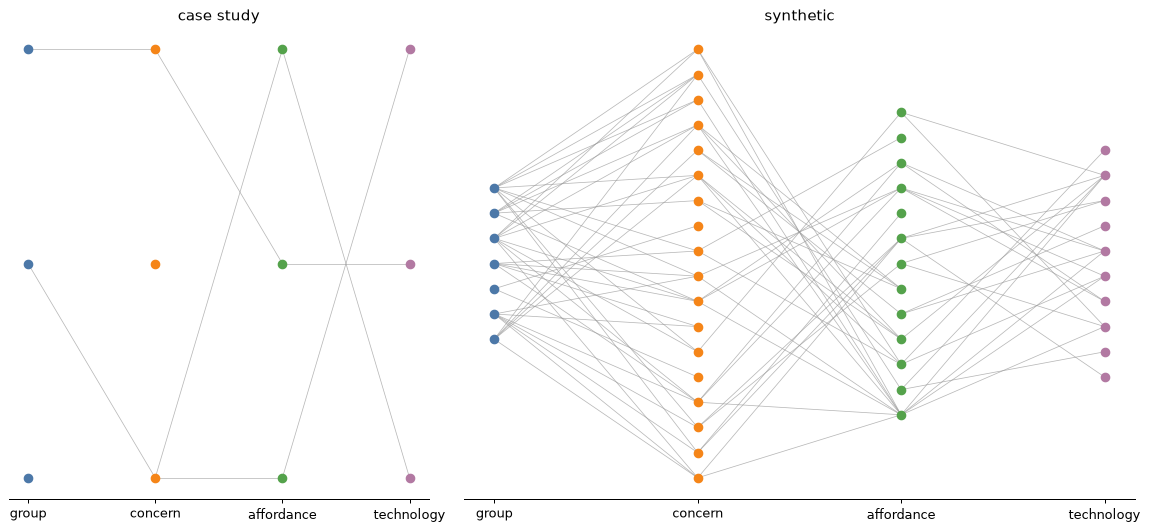

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, (k, m) in zip(axes, VAULTS.items()):
    plots.draw_layered(m, ax, k)
plt.tight_layout(); plt.show()

**Reads as:** the four layers as columns, one dot per page, one line per relation page. A dot with no line to its neighbouring column is a node the chain does not reach (see section 1).

**Does not mean:** position within a column is alphabetical, not importance; line count is the number of relation pages written, not how strongly anything is held or addressed.

## 1. Traceability chains and gaps

Borrowing from requirements traceability: for each concern, who holds it, which affordances address it, which technologies those are attributed to. `sa.traceability`, `sa.group_coverage`, `sa.gaps`.

In [3]:
for k, m in VAULTS.items():
    print("=" * 20, k)
    tr = sa.traceability(m)
    display(tr[["n_holders", "n_affordances", "n_technologies", "chain"]])
    print("Chain depth reached, by concern:"); display(tr["chain"].value_counts().to_frame("concerns"))
    print("Group coverage (concerns held, by how far each reaches):"); display(sa.group_coverage(m))
    print("Gaps (nodes the coded chain does not continue from or to):")
    for label, names in sa.gaps(m).items():
        print(f"  {label}: {names if names else 'none'}")

==================== case study


,n_holders,n_affordances,n_technologies,chain
concern,,,,
anonymity,1,1,1,complete
attribution,0,0,0,unaddressed
intent-without-drift,1,2,2,complete


Chain depth reached, by concern:


,concerns
chain,
complete,2
unaddressed,1


Group coverage (concerns held, by how far each reaches):


,concerns_held,complete,"addressed, no technology",unaddressed
group,,,,
facilitator-analysts,1,1,0,0
project-leads,1,1,0,0
workshop-participants,0,0,0,0


... (3 outputs left out)

,concerns
chain,
complete,15
unaddressed,3


Group coverage (concerns held, by how far each reaches):


,concerns_held,complete,"addressed, no technology",unaddressed
group,,,,
board-volunteers,9,9,0,0
farm-irrigators,5,5,0,0
household-members,8,8,0,0
maintenance-crew,5,4,0,1
school-liaisons,2,0,0,2
treatment-operators,6,5,0,1
watershed-stewards,5,5,0,0


Gaps (nodes the coded chain does not continue from or to):
  groups holding no concern: none
  concerns held by no group: none
  concerns no affordance addresses: ['hands-on-site-visits', 'predictable-maintenance-schedule', 'pupil-learning-access']
  affordances addressing no concern: none
  affordances attributed to no technology: ['community-asset-fund', 'operator-training-course', 'reserve-storage-policy']
  technologies attributed to no affordance: none
  groups whose concerns are all unaddressed: ['school-liaisons']


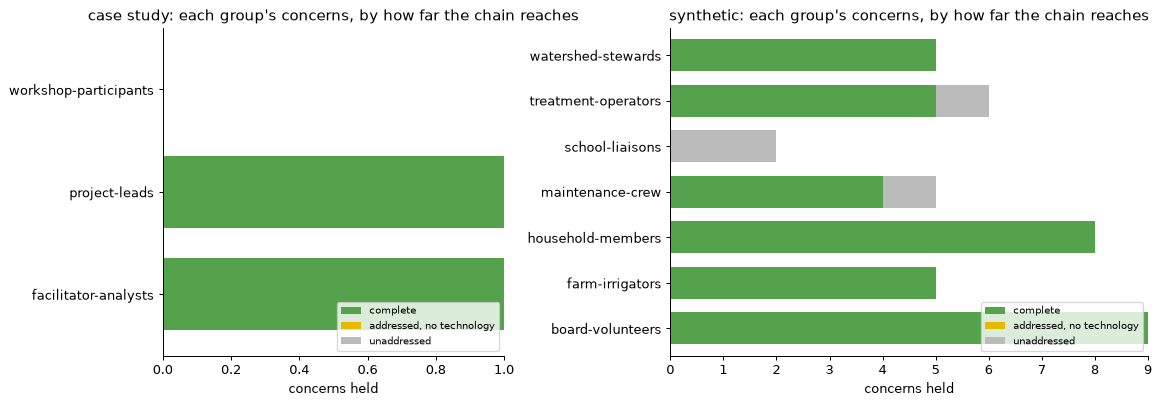

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
for ax, (k, m) in zip(axes, VAULTS.items()):
    plots.plot_coverage(m, ax, f"{k}: each group's concerns, by how far the chain reaches")
plt.tight_layout(); plt.show()

**Reads as:** bars show, for each group, how many held concerns have an affordance and a technology behind them (green), an affordance only (yellow), or nothing (grey). A group with an all-grey bar holds concerns that no recorded affordance addresses. Affordances with no technology are listed above.

**Does not mean:** a grey or short bar is a gap in *what has been coded so far*, not a verdict that the group is neglected or the concern unmet; the vault may simply not have been coded further. Having more green does not make a group, or an architecture, better served. An address link says a coder linked the two, not that it works.

## 2. Bipartite projections

Two one-mode views: groups linked when they hold the same concern, and concerns linked when the same affordance addresses both. Edge weight is the number of shared neighbours. `sa.projections` (table), `sa.projection` (graph).

case study | group projection: edges 0 , isolated groups ['facilitator-analysts', 'project-leads', 'workshop-participants'] | concern projection: edges 0 , components 3
synthetic | group projection: edges 13 , isolated groups ['school-liaisons'] | concern projection: edges 37 , components 6


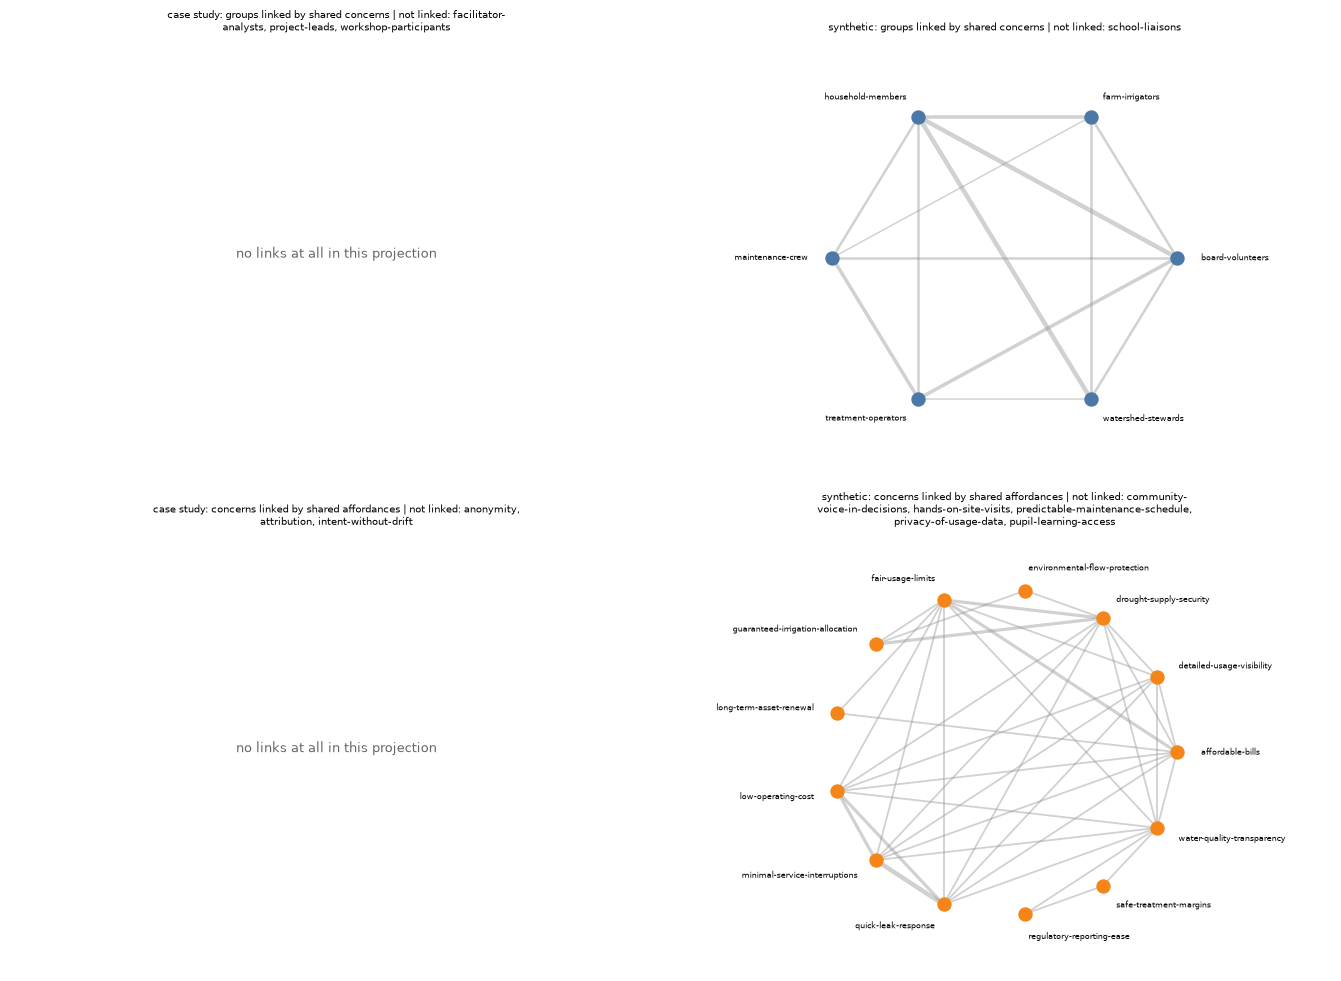

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for j, (k, m) in enumerate(VAULTS.items()):
    plots.draw_projection(m, "stakeholder-group", "concern", axes[0, j], f"{k}: groups linked by shared concerns")
    plots.draw_projection(m, "concern", "affordance", axes[1, j], f"{k}: concerns linked by shared affordances")
    Bg, Bc = sa.projection(m, "stakeholder-group", "concern"), sa.projection(m, "concern", "affordance")
    print(k, "| group projection: edges", Bg.number_of_edges(), ", isolated groups", list(nx.isolates(Bg)),
          "| concern projection: edges", Bc.number_of_edges(), ", components", nx.number_connected_components(Bc))
plt.tight_layout(); plt.show()

In [6]:
p = sa.projections(VAULTS["synthetic"])
display(p[p.projection == "groups by shared concern"].drop(columns="projection"))

,node_a,node_b,shared,via
0,board-volunteers,farm-irrigators,2,"[community-voice-in-decisions, detailed-usage-visibility]"
1,board-volunteers,household-members,4,"[affordable-bills, community-voice-in-decisions, fair-usage-limits, privacy-..."
2,board-volunteers,maintenance-crew,2,"[long-term-asset-renewal, low-operating-cost]"
3,board-volunteers,treatment-operators,3,"[low-operating-cost, regulatory-reporting-ease, safe-treatment-margins]"
4,board-volunteers,watershed-stewards,2,"[community-voice-in-decisions, fair-usage-limits]"
5,farm-irrigators,household-members,3,"[community-voice-in-decisions, drought-supply-security, minimal-service-inte..."
6,farm-irrigators,maintenance-crew,1,[minimal-service-interruptions]
7,farm-irrigators,watershed-stewards,2,"[community-voice-in-decisions, drought-supply-security]"
8,household-members,maintenance-crew,2,"[minimal-service-interruptions, quick-leak-response]"
9,household-members,treatment-operators,2,"[quick-leak-response, water-quality-transparency]"


**Reads as:** an edge between two groups means they hold at least one concern in common (the table names which). Concerns joined by thick edges are concerns addressed by the same affordances. Isolated nodes share nothing with the rest.

**Does not mean:** shared concerns are not agreement; two groups may want the same thing for opposite reasons or at others' cost (see section 3). Projection loses information: a link says nothing about *which* node is the shared one, and a hub node makes a clique of its neighbours. Nodes sit on a ring in alphabetical order; ring position is a drawing convenience, not a measurement.

## 3. Tension: conflicts, and who stands where

`conflicts` are declared on a concern page. Here: every conflicting pair, the groups holding both sides (internal tension), and group pairs holding opposite sides. `sa.tension`.

In [7]:
for k, m in VAULTS.items():
    t = sa.tension(m)
    one_sided = int((t["pairs"].n_declarations == 1).sum())
    print("=" * 20, k, f"| {len(t['pairs'])} conflict pairs, {one_sided} declared on one page only (symmetric closure supplies the other direction)")
    display(t["pairs"])
    print("Groups holding both sides of a pair:"); display(t["both_sides"] if len(t["both_sides"]) else "none")
    print("Group pairs on opposite sides:"); display(t["opposite_sides"] if len(t["opposite_sides"]) else "none")

==================== case study | 1 conflict pairs, 1 declared on one page only (symmetric closure supplies the other direction)


,concern_a,concern_b,declared_by,n_declarations,holders_a,holders_b
0,anonymity,attribution,anonymity,1,[facilitator-analysts],[]


Groups holding both sides of a pair:


'none'

Group pairs on opposite sides:


'none'

... (2 outputs left out)

Groups holding both sides of a pair:


,group,concern_a,concern_b
0,board-volunteers,affordable-bills,long-term-asset-renewal
1,board-volunteers,detailed-usage-visibility,privacy-of-usage-data
2,board-volunteers,low-operating-cost,safe-treatment-margins
3,treatment-operators,low-operating-cost,safe-treatment-margins


Group pairs on opposite sides:


,group_x,concern_x,group_y,concern_y
0,board-volunteers,affordable-bills,maintenance-crew,long-term-asset-renewal
1,household-members,affordable-bills,board-volunteers,long-term-asset-renewal
2,household-members,affordable-bills,maintenance-crew,long-term-asset-renewal
3,board-volunteers,detailed-usage-visibility,household-members,privacy-of-usage-data
4,farm-irrigators,detailed-usage-visibility,board-volunteers,privacy-of-usage-data
5,farm-irrigators,detailed-usage-visibility,household-members,privacy-of-usage-data
6,watershed-stewards,environmental-flow-protection,farm-irrigators,guaranteed-irrigation-allocation
7,board-volunteers,fair-usage-limits,farm-irrigators,guaranteed-irrigation-allocation
8,household-members,fair-usage-limits,farm-irrigators,guaranteed-irrigation-allocation
9,watershed-stewards,fair-usage-limits,farm-irrigators,guaranteed-irrigation-allocation


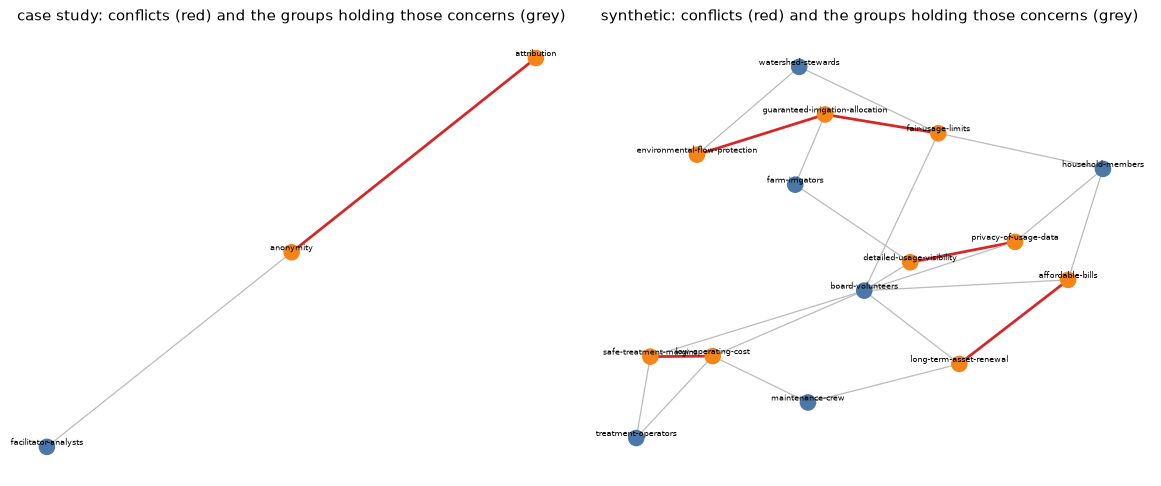

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (k, m) in zip(axes, VAULTS.items()):
    plots.draw_tension(m, ax, f"{k}: conflicts (red) and the groups holding those concerns (grey)")
plt.tight_layout(); plt.show()

**Reads as:** red edges join concerns declared to conflict; grey edges join a group to a concern it holds. A group touching both ends of a red edge holds both sides itself; two groups touching opposite ends are on opposite sides. In the tables, a group can appear in both lists.

**Does not mean:** a conflict is a declared tension between interests, not a disagreement that has occurred, and not a flaw to be removed. A group holding both sides is carrying a trade-off, not being inconsistent. Opposite sides are not adversaries. A concern with no conflict edge may simply not have been compared with the others; absence of a declared conflict is not harmony.

## 4. Centrality and brokerage

Which affordances and technologies carry how many concerns? Three descriptive counts: concerns carried (every concern upstream of the node), groups behind it, and betweenness (the share of shortest paths between other nodes that pass through it, on the undirected typed graph). `sa.centrality`. Tables are alphabetical.

==================== case study


,layer,concerns_carried,groups_behind,degree,betweenness
node,,,,,
archive-tags,technology,1,1,1,0.000
cap-setting,technology,1,1,1,0.000
gated-approval,affordance,1,1,2,0.073
groups-clustered-under-a-cap,affordance,1,1,2,0.036
main-and-dev-branches,technology,1,1,1,0.000
revert-with-history-kept,affordance,1,1,2,0.073


==================== synthetic


,layer,concerns_carried,groups_behind,degree,betweenness
node,,,,,
anonymised-usage-sharing,affordance,1,2,3,0.009
billing-system,technology,3,4,1,0.000
community-asset-fund,affordance,1,2,1,0.000
emergency-repair-roster,affordance,2,4,4,0.020
leak-alert-notifications,affordance,3,5,6,0.048
member-portal,technology,13,6,5,0.087
operator-training-course,affordance,1,2,1,0.000
public-quality-reports,affordance,3,4,6,0.094
regulator-report-export,affordance,1,2,3,0.012


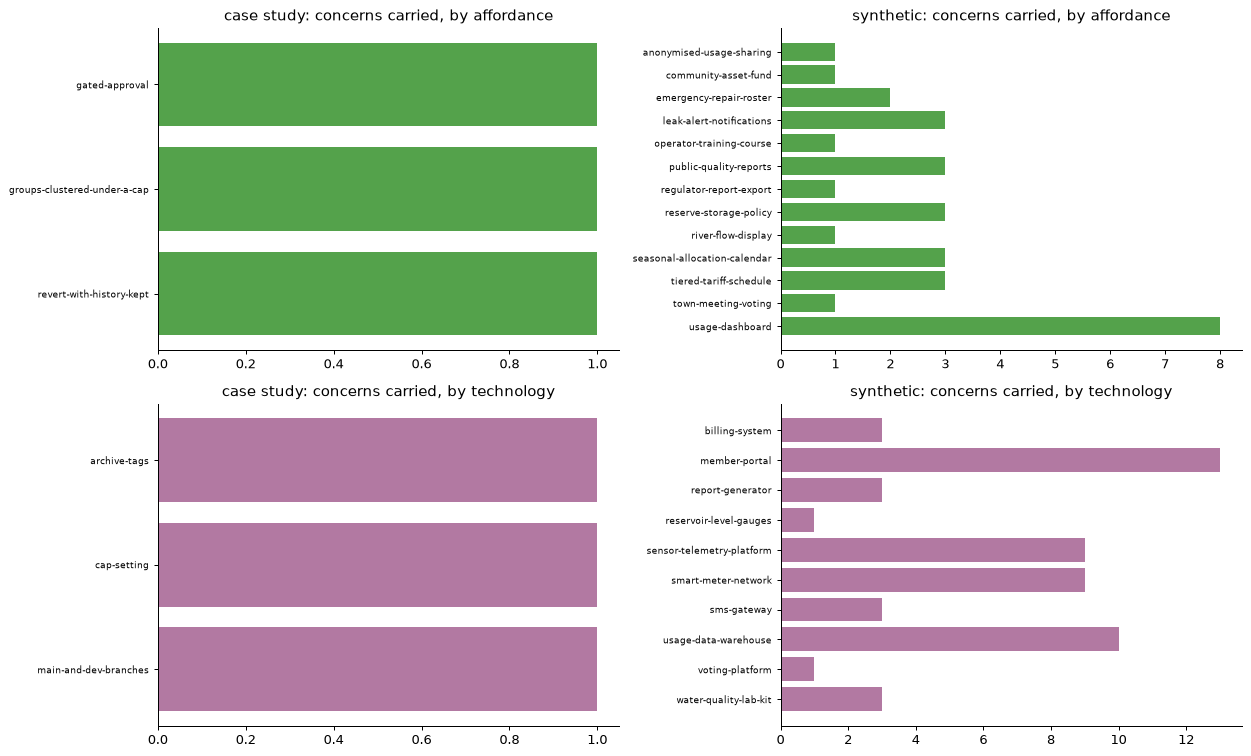

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for j, (k, m) in enumerate(VAULTS.items()):
    print("=" * 20, k); display(sa.centrality(m))
    for i, layer in enumerate(["affordance", "technology"]):
        plots.plot_carriage(m, layer, axes[i, j], f"{k}: concerns carried, by {layer}")
plt.tight_layout(); plt.show()

**Reads as:** a long bar is a node that many recorded concerns pass through on their way to something concrete: where the structure concentrates, so where a change would touch many concerns, and where a concern would have no other route. High betweenness says the node sits between otherwise separate parts of the graph (a broker). Zero betweenness (every leaf has it) only says no shortest path passes through the node.

**Does not mean:** carrying many concerns is not importance, quality or risk by itself, and carrying few is not weakness; the count depends on how finely concerns were written and how many records were coded. These are descriptions of this vault's coding, not properties of the real system. Do not compare counts across the two vaults.

## 5. Community structure

Do the four layers fall into clusters that cut across them? Two standard algorithms on the undirected graph (greedy modularity, Louvain with a fixed seed), compared on how many same-cluster node pairs they agree on. `sa.communities`, `sa.community_agreement`.

==================== case study | greedy modularity: 3 clusters, louvain (seed 1): 3 clusters | pair agreement between the two: 0.53
  cluster 0: groups ['facilitator-analysts'] | concerns 1 | affordances 1 | technologies 1
  cluster 1: groups [] | concerns 0 | affordances 1 | technologies 1
  cluster 2: groups ['project-leads'] | concerns 1 | affordances 1 | technologies 1
==================== synthetic | greedy modularity: 7 clusters, louvain (seed 1): 6 clusters | pair agreement between the two: 0.31
  cluster 0: groups ['household-members', 'watershed-stewards'] | concerns 3 | affordances 1 | technologies 1
  cluster 1: groups [] | concerns 2 | affordances 2 | technologies 2
  cluster 2: groups ['board-volunteers', 'maintenance-crew'] | concerns 3 | affordances 1 | technologies 0
  cluster 3: groups ['farm-irrigators'] | concerns 4 | affordances 2 | technologies 0
  cluster 4: groups [] | concerns 2 | affordances 4 | technologies 4
  cluster 5: groups ['school-liaisons'] | concerns

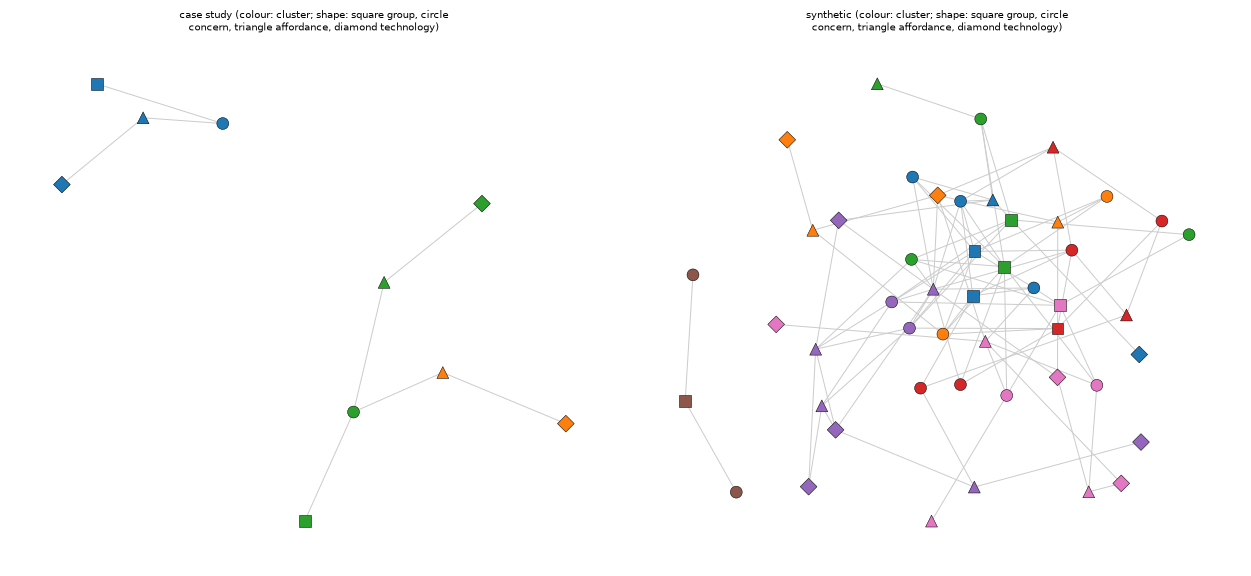

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (k, m) in zip(axes, VAULTS.items()):
    comm = sa.communities(m, seed=1)
    print("=" * 20, k, f"| greedy modularity: {comm.greedy_modularity.nunique()} clusters, louvain (seed 1): {comm.louvain.nunique()} clusters",
          f"| pair agreement between the two: {sa.community_agreement(comm):.2f}")
    for c, grp in comm.groupby("greedy_modularity"):
        n = grp.layer.value_counts()
        print(f"  cluster {c}: groups {sorted(grp[grp.layer == 'stakeholder-group'].node)} | concerns {n.get('concern', 0)} | affordances {n.get('affordance', 0)} | technologies {n.get('technology', 0)}")
    plots.draw_communities(m, ax, k)
plt.tight_layout(); plt.show()

**Reads as:** each colour is a set of nodes that are more densely linked to each other than to the rest, typically one group with its concerns and the affordances and technologies behind them. Clusters that hold several groups are where groups share structure. Where the two algorithms agree on few pairs, the structure is not sharply clustered, and any one partition should be held loosely.

**Does not mean:** clusters are not teams, workstreams or architectures; they are a by-product of how the vault was coded, and a hub (see section 4) can pull otherwise distinct parts together. A cluster is not a better or worse grouping, and different algorithms or seeds give different partitions.

## 6. Provenance: what the coded records name

Each coded scenario or architecture record names groups, concerns, affordances and (architectures) technologies. Here: which nodes each record names, and which records name both ends of a conflicting pair. `sa.provenance`, `sa.provenance_matrix`, `sa.conflict_records`.

==================== case study


,role,affordances,concerns,groups,technologies
record,kind,,,,
false-start-and-clean-restart-coded,scenario,2,1,1,0
groups-under-a-cap-pitch-coded,architecture,1,1,0,1
notes-at-a-chatham-house-session-coded,scenario,1,2,2,0
two-branches-and-tags-pitch-coded,architecture,2,1,0,2


Records naming both ends of a conflict:


,record,concern_a,concern_b
0,notes-at-a-chatham-house-session-coded,anonymity,attribution


==================== synthetic


,role,affordances,concerns,groups,technologies
record,kind,,,,
budget-evening-coded,scenario,2,3,4,0
dry-july-allocation-talk-coded,scenario,3,4,3,0
lean-volunteer-pitch-coded,architecture,3,3,0,3
night-main-break-coded,scenario,2,3,3,0
portal-first-pitch-coded,architecture,3,4,0,4
school-visit-day-coded,scenario,1,3,2,0
sensor-first-pitch-coded,architecture,3,4,0,4


Records naming both ends of a conflict:


'none'

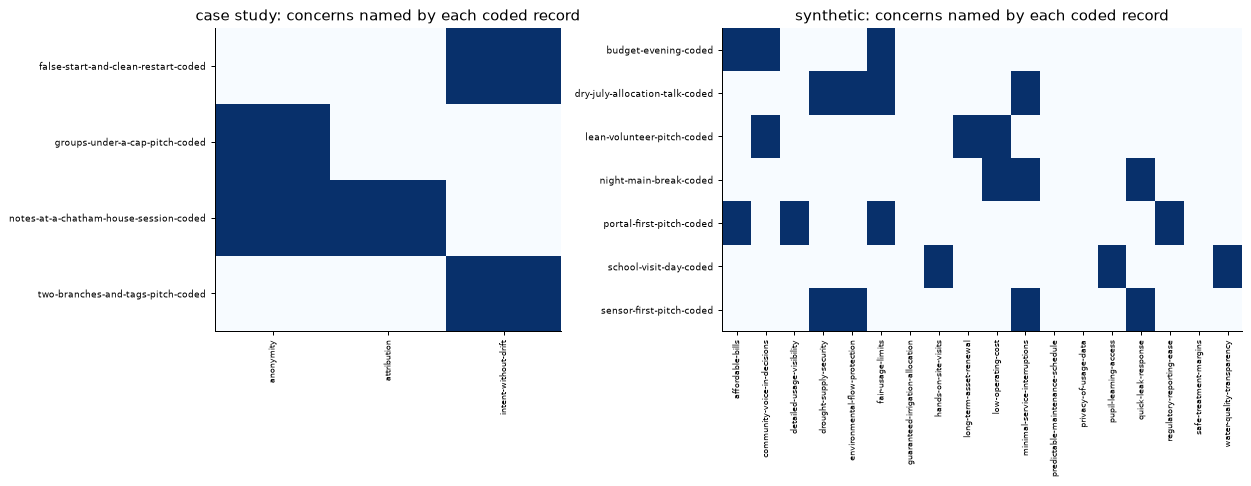

In [11]:
for k, m in VAULTS.items():
    long = sa.provenance(m)
    print("=" * 20, k); display(long.pivot_table(index=["record", "kind"], columns="role", values="node", aggfunc="count", fill_value=0))
    cr = sa.conflict_records(m)
    print("Records naming both ends of a conflict:"); display(cr if len(cr) else "none")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
for ax, (k, m) in zip(axes, VAULTS.items()):
    plots.plot_provenance(m, ax, f"{k}: concerns named by each coded record")
plt.tight_layout(); plt.show()

**Reads as:** dark cells are concerns a record names. Columns with no dark cell are concerns no coded record mentions; rows show how much of the vault each record touches. Records that name both ends of a conflict are where that tension surfaces in the evidence.

**Does not mean:** a record naming more concerns is not a fuller or better account, and an architecture naming fewer is not narrower in any judged sense; records differ in what they were written to cover. Coverage here is of what was coded, not of the real world.

## What this package needed from `scat_kg`

- `scat_kg.vault.read_vault` (internal): the only way to obtain parsed pages and links; the public API has no loader.
- Nothing else beyond `Page.type`, `.name`, `.status`, `.fields["title"]` and `.fm_links`.
- Everything else (typed graph, symmetric conflicts, flattened relations, record table, status filter) was rebuilt in `scat_analysis`; see `../readout.md` for what the tools could provide instead.